# Thorlabs Zelux — Linux / Jupyter test
New code: `Equipments/ThorCamLinux/`. The old `Equipments/ThorCam/` is unchanged.

**Run cells individually.** Hardware access is disabled until you enable `RUN_HARDWARE`. No packages or system rules are installed automatically. The kernel must run on the camera-connected machine. See `Equipments/ThorCamLinux/README.md` for Linux SDK, Python environment, native libraries and USB permissions.

Snapshots preserve raw pixels; preview and MP4 are 8-bit raw grayscale (also for Bayer sensors). Stop live preview before scripted acquisition.

In [5]:
from pathlib import Path
import json
import sys

# Run with the project root as the working directory.
from Equipments.ThorCamLinux import Camera, LiveMonitor, diagnostics, list_cameras, output_path, save_frame


RUN_HARDWARE = True  # Change to True AFTER reviewing diagnostics.
SERIAL = None         # Auto-select only if exactly one camera is detected.
SAVE_DIRECTORY = Path('./camera_data').resolve()  # On the kernel machine.
EXPOSURE_US = 1

if 'camera' not in globals():
    camera = None
if 'monitor' not in globals():
    monitor = None
print(json.dumps(diagnostics(), indent=2))
print('Save directory:', SAVE_DIRECTORY)


{
  "python": "/home/fengxy/miniconda3/bin/python",
  "python_version": "3.14.7",
  "platform": "Linux-6.8.0-146-generic-x86_64-with-glibc2.39",
  "LD_LIBRARY_PATH": "",
  "packages": {
    "thorlabs_tsi_sdk": true,
    "numpy": true,
    "ipywidgets": true,
    "PIL": true,
    "tifffile": true,
    "cv2": true
  },
  "thorlabs_usb": "Bus 002 Device 004: ID 1313:4002 ThorLabs TSI",
  "usb_permissions": [
    {
      "path": "/dev/bus/usb/002/004",
      "read_write_access": true
    }
  ]
}
Save directory: /home/fengxy/ExperimentCode/camera_data


## 1. Discover and connect
If `thorlabs_tsi_sdk` is missing, install the vendor Python wrapper and Linux native SDK first. If `read_write_access` is false, install the vendor udev rules and reconnect. Restart Jupyter after changing native library paths. Close other camera applications.

Optional UI/storage packages can be installed with `%pip install -r Equipments/ThorCamLinux/requirements.txt` in this kernel; this does **not** install the vendor SDK.

In [6]:
if RUN_HARDWARE:
    if camera is not None:
        raise RuntimeError('A camera object already exists. Run cleanup before reconnecting.')
    serials = list_cameras()
    print('Detected serials:', serials)
    camera = Camera(SERIAL)
    print('Connected:', camera.serial)
else:
    print('Hardware disabled. Review diagnostics, then set RUN_HARDWARE = True.')


RuntimeError: A camera object already exists. Run cleanup before reconnecting.

## 2. Capture one frame directly from a script
The returned `frame.image` is an owned, read-only NumPy array. Convert to floating point before background subtraction. Capture disarms the camera on exit.

{
  "serial": "33834",
  "frame_number": 1,
  "host_time_ns": 1793635758252506374,
  "camera_time_ns": 21303000000,
  "bit_depth": 10,
  "exposure_us": 40,
  "sensor_type": "0",
  "shape": [
    1080,
    1440
  ],
  "dtype": "uint16"
}


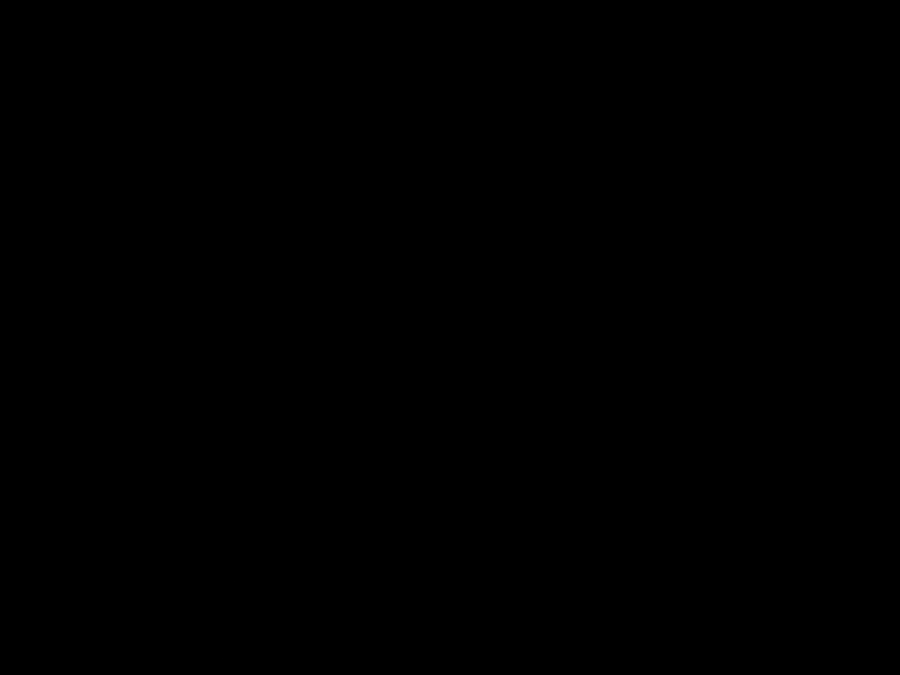

In [3]:
if RUN_HARDWARE and camera is not None:
    if monitor is not None:
        monitor.stop()
    frame = camera.capture(exposure_us=EXPOSURE_US, timeout_s=3)
    print(json.dumps(frame.metadata(), indent=2))
    from PIL import Image
    from IPython.display import display
    preview = Image.fromarray(frame.preview())
    preview.thumbnail((900, 700))
    display(preview)
    # Example analysis input (avoids uint16 subtraction underflow):
    image_float = frame.image.astype('float64')


In [14]:
SAVE_CAPTURE = True  # Opt in to writing an image and JSON metadata.
if RUN_HARDWARE and SAVE_CAPTURE:
    # TIFF needs tifffile; .npy is available with NumPy only.
    image_path = output_path(SAVE_DIRECTORY, '95-105MHz_15tones_cali_3', '.tif')
    print('Saved:', save_frame(frame, image_path))


Saved: /home/fengxy/ExperimentCode/camera_data/95-105MHz_15tones_cali_3_20261102T032512_791521Z_b66ad9f8.tif


## 3. Embedded live monitor
Click **Start preview**. Edit exposure/gain/FPS and click **Apply settings** (stop recording first). Set **Save folder** and **Prefix**, then use **Save snapshot** or **Record MP4** / **Stop recording**. The snapshot uses the latest acquired frame.

Cam FPS = 0 disables the camera frame-rate limiter when supported. MP4 FPS is playback speed, not measured capture rate. Video uses a bounded queue; dropped frames and frame-number gaps are reported. Keep raw TIFF/NPY images for measurements. Stop preview before the next section.

In [4]:
if RUN_HARDWARE and camera is not None:
    if monitor is not None:
        monitor.close()
    monitor = LiveMonitor(camera, directory=SAVE_DIRECTORY, preview_fps=8)
    monitor.exposure.value = EXPOSURE_US
    monitor.show()


## 4. External-trigger experiment cycle (optional)
This cell does not configure or fire the BNC575 automatically. Supply a `start_experiment_cycle(label)` callback that configures and starts your existing pulse sequence, producing exactly one camera trigger per call. Verify electrical trigger compatibility against the camera manual.

The camera is armed **before** the callback runs. Choose a timeout covering the entire trigger delay plus exposure/readout (15 s is only an example for your ~10.5 s cycle). No software trigger is issued. The camera stays armed across the three shots and is always disarmed afterward.

In [ ]:
RUN_EXTERNAL_TEST = False
SAVE_EXPERIMENT = False

# Replace None with your own function, e.g. a function calling
# bnc575.pulse_sequence_setup(...) and bnc575.start_pulses().
start_experiment_cycle = None

if RUN_HARDWARE and RUN_EXTERNAL_TEST:
    if camera is None or not callable(start_experiment_cycle):
        raise RuntimeError('Connect the camera and supply start_experiment_cycle first.')
    if monitor is not None:
        monitor.stop()
    camera.configure(exposure_us=900, trigger='external')
    experiment_frames = {}
    try:
        camera.arm()
        for label in ('atoms', 'reference', 'dark'):
            start_experiment_cycle(label)
            shot = camera.read_frame(timeout_s=15)
            experiment_frames[label] = shot
            print(label, shot.frame_number, shot.image.shape)
            if SAVE_EXPERIMENT:
                save_frame(shot, output_path(SAVE_DIRECTORY, label, '.tif'))
    finally:
        camera.disarm()


## 5. Cleanup — run when finished
Set `CLOSE_CAMERA = True` and run this cell before reconnecting, switching camera programs, or restarting the kernel. Stop the monitor before closing its borrowed camera. If a native call is stuck, the code reports that rather than closing a camera still in use.

In [8]:
CLOSE_CAMERA = False
if CLOSE_CAMERA:
    if monitor is not None:
        monitor.close()
        monitor = None
    if camera is not None:
        camera.close()
        camera = None
    print('Camera and monitor closed.')
